# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict

## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [2]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, train_size=0.7, random_state=241
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (309, 10)
Размер тестовой выборки: (133, 10)


__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [3]:
# Нужные классы Ridge, Lasso и numpy уже импортированы выше.

Коэффициенты Ridge:
[  20.86588099  -58.00039065  231.2704688   186.67010355   33.31087207
   -2.16994737 -150.95049376  141.35036492  250.75391278  123.18025806]

Коэффициенты Lasso:
[  0.           0.         274.33128438  48.57203696   0.
   0.          -0.           0.         424.12142666   0.        ]

Близких к нулю у Ridge: 0
Близких к нулю у Lasso: 7


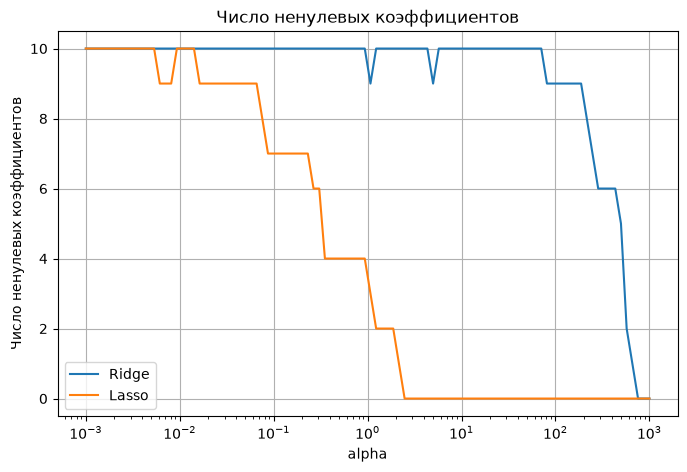

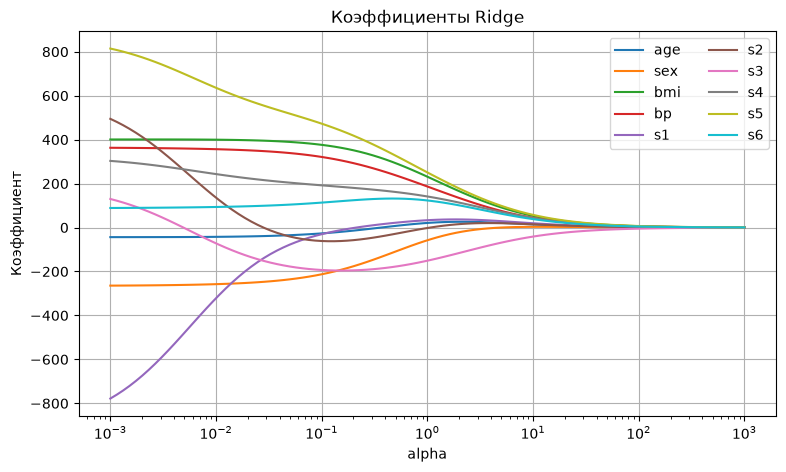

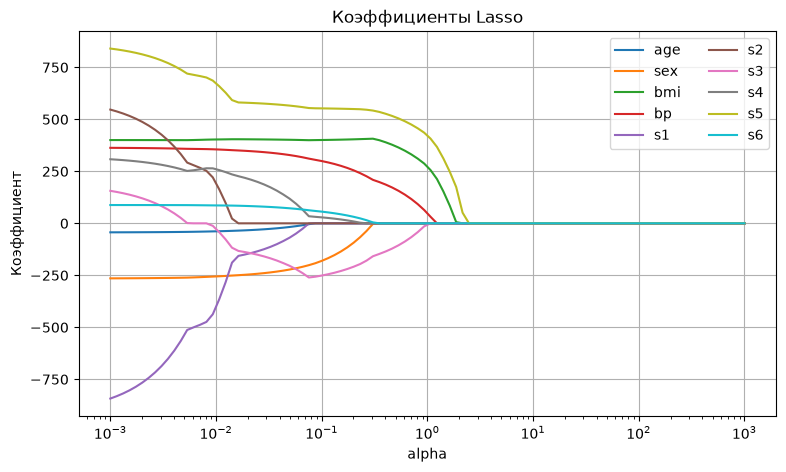

In [4]:
# Обучаем модели с параметрами по умолчанию (alpha=1)
ridge = Ridge()
lasso = Lasso(max_iter=100000)

ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

print("Коэффициенты Ridge:")
print(ridge.coef_)
print("\nКоэффициенты Lasso:")
print(lasso.coef_)

# Считаем коэффициент близким к нулю, если |coef| < 1
limit = 1
print("\nБлизких к нулю у Ridge:", np.sum(np.abs(ridge.coef_) < limit))
print("Близких к нулю у Lasso:", np.sum(np.abs(lasso.coef_) < limit))

# Обучаем модели с разными alpha
alphas = np.logspace(-3, 3, 100)
ridge_coefs = []
lasso_coefs = []
ridge_nonzero = []
lasso_nonzero = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    lasso = Lasso(alpha=alpha, max_iter=100000)

    ridge.fit(X_train, y_train)
    lasso.fit(X_train, y_train)

    ridge_coefs.append(ridge.coef_)
    lasso_coefs.append(lasso.coef_)
    ridge_nonzero.append(np.sum(np.abs(ridge.coef_) >= limit))
    lasso_nonzero.append(np.sum(np.abs(lasso.coef_) >= limit))

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

# Число ненулевых коэффициентов
plt.figure(figsize=(8, 5))
plt.semilogx(alphas, ridge_nonzero, label="Ridge")
plt.semilogx(alphas, lasso_nonzero, label="Lasso")
plt.xlabel("alpha")
plt.ylabel("Число ненулевых коэффициентов")
plt.title("Число ненулевых коэффициентов")
plt.legend()
plt.grid()
plt.show()

# Коэффициенты Ridge
plt.figure(figsize=(9, 5))
for i in range(X_train.shape[1]):
    plt.semilogx(alphas, ridge_coefs[:, i], label=data.feature_names[i])
plt.xlabel("alpha")
plt.ylabel("Коэффициент")
plt.title("Коэффициенты Ridge")
plt.legend(ncol=2)
plt.grid()
plt.show()

# Коэффициенты Lasso
plt.figure(figsize=(9, 5))
for i in range(X_train.shape[1]):
    plt.semilogx(alphas, lasso_coefs[:, i], label=data.feature_names[i])
plt.xlabel("alpha")
plt.ylabel("Коэффициент")
plt.title("Коэффициенты Lasso")
plt.legend(ncol=2)
plt.grid()
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [5]:
# В новых версиях sklearn cross_val_score находится в model_selection.
# Он уже импортирован в первой ячейке.

In [6]:
ridge = Ridge()
ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)

rmse_default = np.sqrt(mean_squared_error(y_test, y_pred))
mae_default = mean_absolute_error(y_test, y_pred)
r2_default = r2_score(y_test, y_pred)

print("Ridge с alpha=1")
print("RMSE:", round(rmse_default, 4))
print("MAE: ", round(mae_default, 4))
print("R2:  ", round(r2_default, 4))

Ridge с alpha=1
RMSE: 58.3043
MAE:  49.6028
R2:   0.3599


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

Лучший alpha по RMSE: 0.001
Лучший alpha по MAE:  0.0011497569953977356
Лучший alpha по R2:   0.05722367659350217


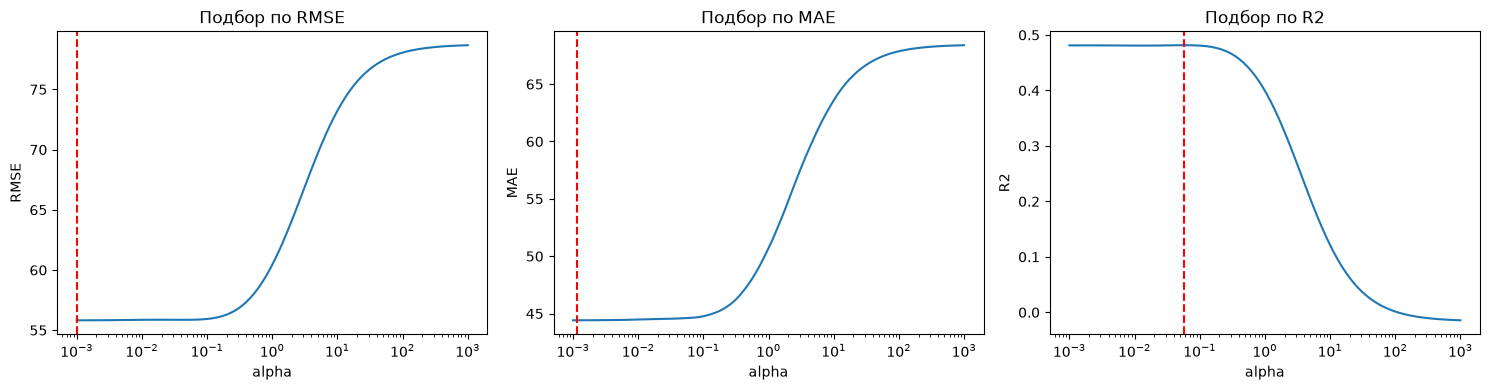

,Подбор,alpha,RMSE,MAE,R2
0,По RMSE,0.001000,55.857555,47.155430,0.412498
1,По MAE,0.001150,55.850901,47.150097,0.412638
2,По R2,0.057224,55.653553,47.172464,0.416782


In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=241)

rmse_scores = []
mae_scores = []
r2_scores = []

# Для каждого alpha считаем среднюю метрику по 5 фолдам
for alpha in alphas:
    model = Ridge(alpha=alpha)

    rmse = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_root_mean_squared_error"
    ).mean()

    mae = -cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="neg_mean_absolute_error"
    ).mean()

    r2 = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="r2"
    ).mean()

    rmse_scores.append(rmse)
    mae_scores.append(mae)
    r2_scores.append(r2)

# Находим лучшие alpha
best_alpha_rmse = alphas[np.argmin(rmse_scores)]
best_alpha_mae = alphas[np.argmin(mae_scores)]
best_alpha_r2 = alphas[np.argmax(r2_scores)]

print("Лучший alpha по RMSE:", best_alpha_rmse)
print("Лучший alpha по MAE: ", best_alpha_mae)
print("Лучший alpha по R2:  ", best_alpha_r2)

# Графики качества
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.semilogx(alphas, rmse_scores)
plt.axvline(best_alpha_rmse, color="red", linestyle="--")
plt.xlabel("alpha")
plt.ylabel("RMSE")
plt.title("Подбор по RMSE")

plt.subplot(1, 3, 2)
plt.semilogx(alphas, mae_scores)
plt.axvline(best_alpha_mae, color="red", linestyle="--")
plt.xlabel("alpha")
plt.ylabel("MAE")
plt.title("Подбор по MAE")

plt.subplot(1, 3, 3)
plt.semilogx(alphas, r2_scores)
plt.axvline(best_alpha_r2, color="red", linestyle="--")
plt.xlabel("alpha")
plt.ylabel("R2")
plt.title("Подбор по R2")

plt.tight_layout()
plt.show()

# Проверяем подобранные модели на тестовой выборке
rows = []

for name, alpha in [
    ("По RMSE", best_alpha_rmse),
    ("По MAE", best_alpha_mae),
    ("По R2", best_alpha_r2),
]:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    rows.append([
        name,
        alpha,
        np.sqrt(mean_squared_error(y_test, pred)),
        mean_absolute_error(y_test, pred),
        r2_score(y_test, pred),
    ])

results = pd.DataFrame(
    rows,
    columns=["Подбор", "alpha", "RMSE", "MAE", "R2"]
)
results

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

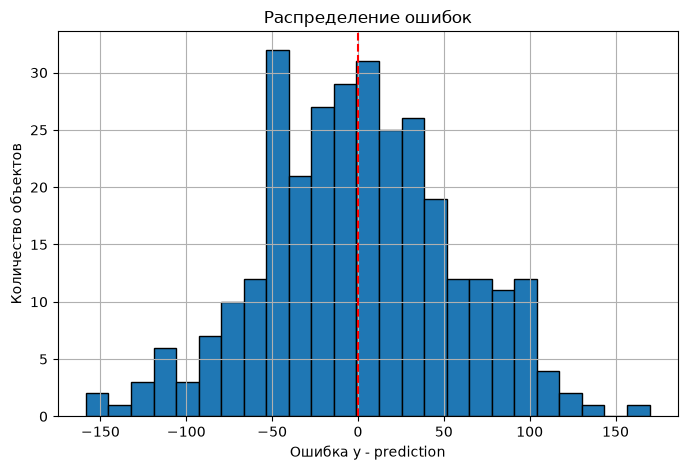

Минимальная ошибка: -158.42
Максимальная ошибка: 169.8
Средняя ошибка:      0.5

Есть несколько больших ошибок в хвостах распределения.


In [8]:
# Out-of-fold прогноз: каждый объект предсказывает модель,
# которая не обучалась на этом объекте
model = Ridge(alpha=best_alpha_rmse)
train_pred = cross_val_predict(model, X_train, y_train, cv=cv)
errors = y_train - train_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=25, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Ошибка y - prediction")
plt.ylabel("Количество объектов")
plt.title("Распределение ошибок")
plt.grid()
plt.show()

print("Минимальная ошибка:", round(errors.min(), 2))
print("Максимальная ошибка:", round(errors.max(), 2))
print("Средняя ошибка:     ", round(errors.mean(), 2))
print("\nЕсть несколько больших ошибок в хвостах распределения.")

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [9]:
# Ищем выбросы по правилу 1.5 * IQR
q1 = np.quantile(errors, 0.25)
q3 = np.quantile(errors, 0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

good_objects = (errors >= lower) & (errors <= upper)

print("Нижняя граница:", round(lower, 2))
print("Верхняя граница:", round(upper, 2))
print("Удалено объектов:", np.sum(~good_objects))

# Модель до удаления выбросов
model_before = Ridge(alpha=best_alpha_rmse)
model_before.fit(X_train, y_train)
pred_before = model_before.predict(X_test)

# Модель после удаления выбросов
model_after = Ridge(alpha=best_alpha_rmse)
model_after.fit(X_train[good_objects], y_train[good_objects])
pred_after = model_after.predict(X_test)

comparison = pd.DataFrame({
    "До удаления": [
        np.sqrt(mean_squared_error(y_test, pred_before)),
        mean_absolute_error(y_test, pred_before),
        r2_score(y_test, pred_before),
    ],
    "После удаления": [
        np.sqrt(mean_squared_error(y_test, pred_after)),
        mean_absolute_error(y_test, pred_after),
        r2_score(y_test, pred_after),
    ],
}, index=["RMSE", "MAE", "R2"])

comparison

# MAE немного уменьшилась, но RMSE выросла, а R2 снизился.
# Значит, удаление выбросов не дало однозначного улучшения.

Нижняя граница: -154.1
Верхняя граница: 150.19
Удалено объектов: 3


,До удаления,После удаления
RMSE,55.857555,56.012076
MAE,47.155430,47.061513
R2,0.412498,0.409243


__Задание 3.__ Отчёт

**(2 балла)**

In [10]:
print("ИТОГОВЫЙ ОТЧЁТ")
print()
print("1. Данные разделены на train и test в отношении 70/30.")
print("2. Ridge плавно уменьшает коэффициенты, Lasso может занулять их.")
print("3. После подбора alpha качество Ridge стало лучше.")
print("4. Выбросы найдены по out-of-fold ошибкам и правилу IQR.")
print("5. Удаление 3 выбросов не улучшило все метрики.")
print()
print("Главный вывод:")
print("alpha нужно подбирать по кросс-валидации на train.")
print("Большая ошибка не всегда означает, что объект нужно удалить.")

ИТОГОВЫЙ ОТЧЁТ

1. Данные разделены на train и test в отношении 70/30.
2. Ridge плавно уменьшает коэффициенты, Lasso может занулять их.
3. После подбора alpha качество Ridge стало лучше.
4. Выбросы найдены по out-of-fold ошибкам и правилу IQR.
5. Удаление 3 выбросов не улучшило все метрики.

Главный вывод:
alpha нужно подбирать по кросс-валидации на train.
Большая ошибка не всегда означает, что объект нужно удалить.
